# 4. Solving partial differential equations

**Pin number**: 

In [1]:
# Define here variables PIN and C and assign appropriate values to them

import numpy as np
import matplotlib.pyplot as plt

PIN = 239
C = 5 - PIN/100


### Jacobi methods

**Question 1.** Implement the function Phi(N) that takes as input the size $N$ of the grid and returns an array with the values of the exact solution at the grid points. Print Phi(13)[5][6].

In [2]:
# Use this cell to implement the function Phi(N)

def Phi(N):
    phi = np.zeros((N+2, N+2))

    # Define grid coordinates
    x = [i/(N+1) for i in range(N+2)]
    y = [j/(N+1) for j in range(N+2)]

    # Fill ALL points using exact solution
    for i in range(N+2):
        for j in range(N+2):
            phi[i, j] = C*(x[i]**2 - y[j]**2) + x[i]*y[j]

    return phi

# Test
val = Phi(13)[5][6]
print(val)


0.006581632653061303


**Question 2.** Implement the function Jacobi(sigma,N,k) that takes as inputs the relaxation parameter $\sigma$, the grid size $N$ and the number of iterations $k$ and returns the calculated array for the numerical solution $\phi$ after $k$ iterations  using the Jacobi method. Print Jacobi(1,3,5).

In [3]:
# Use this cell to implement the function Jacobi(sigma,N,k)

def Jacobi(sigma, N, k):
    jac = np.zeros((N+2, N+2))

    for i in range(0, N+2):
        jac[i, 0] = i/(N+1)

    for j in range(0, N+2):
        jac[0, j] = j/(N+1)
    
    phi_old = jac
    phi_new = jac
    
    for _ in range(k):
            for i in range(1, N+1):
                for j in range(1, N+1):
                    phi_new[i,j] = (1 - sigma)*phi_old[i,j] + sigma * 0.25 * (phi_old[i+1,j] + phi_old[i-1,j] + phi_old[i,j+1] + phi_old[i,j-1])
    return phi_new

print(Jacobi(1, 3, 5))




[[0.         0.25       0.5        0.75       1.        ]
 [0.25       0.28388977 0.3285408  0.30712891 0.        ]
 [0.5        0.3285408  0.23925781 0.15534353 0.        ]
 [0.75       0.30712891 0.15534353 0.07767177 0.        ]
 [1.         0.         0.         0.         0.        ]]


**Question 3.** Fix $N=13$ and produce a plot showing the error $e(0.5,0.5)$ as well as the relative error $e_{rel}(0.5,0.5)$ as defined in the manual for the number of iterations $1\leq k\leq 200$.

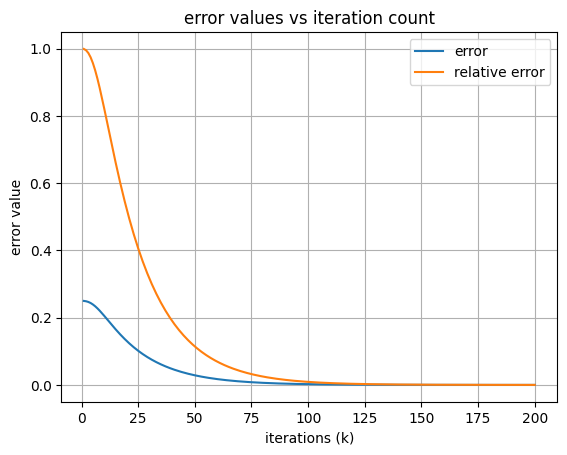

In [4]:
# Use this cell to produce a plot showing e(0.5,0.5) and erel(0.5,0.5)

N = 13

def compute_errors(phi_exact, phi_num, N):
    center = (N+1)//2
    
    exact_val = phi_exact[center, center]
    num_val = phi_num[center, center]
    
    e = abs(exact_val - num_val)
    erel = e / abs(exact_val)
    
    return e, erel

phi_exact = Phi(N)

K = []
errors = []
rel_errors = []

for k in range(1, 201):
    phi_num = Jacobi(1, N, k)
    e, erel = compute_errors(phi_exact, phi_num, N)
    
    errors.append(e)
    rel_errors.append(erel)
    K.append(k)


plt.grid()
plt.title("error values vs iteration count")
plt.xlabel("iterations (k)")
plt.ylabel("error value")
plt.plot(K, errors, label="error")
plt.plot(K, rel_errors, label="relative error")
plt.legend()
plt.show()


The relative error at position $(0.5,0.5)$ decreases below 1% for $k_N\approx...$ 60


**Question 4.** Implement the function kN(sigma,N,Phi) that takes as parameters the relaxation parameter $\sigma$, the grid size $N$ and the true solution $\Phi$ for the given grid size and returns the critical number of iterations $k_N$ for which $e_{rel}(0.5,0.5)$ for the Jacobi method decreases below 0.01.

In [5]:
# Use this cell to implement kN(sigma,N,Phi)

def kN(sigma, N, Phi_exact):

    k = 0
    max_iter = 110000
    phi_exact = Phi(N)

    while k < max_iter:
        phi_num = Jacobi(1, N, k)
        e, erel = compute_errors(phi_exact, phi_num, N)
        k += 1


        if erel < 0.01:
            return k

    return 110000

Phi_exact = Phi(N)
print(kN(1, N, Phi_exact))



99


**Question 5.** Produce a scatter plot showing $\log{k_N}$ against $\log{N}$ for $N=1,3,5,7,9,11,13$. Also include a linear fit of the data into your figure.

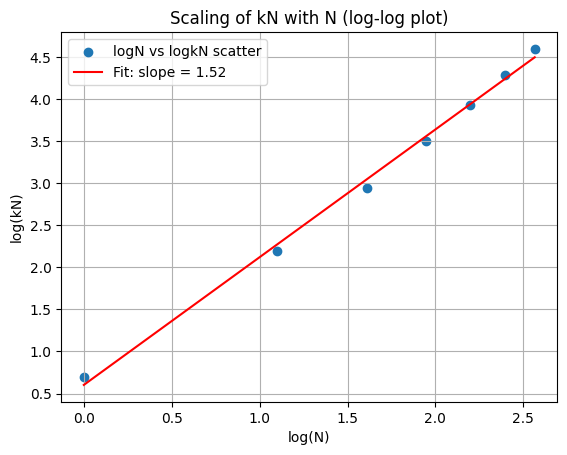

In [6]:
# Use this cell to plot log(kN) against log(N) and its linear fit
N_values = list(range(1, 14, 2))
kN_values = []


for N in N_values:
    phi_exact = Phi(N)
    k_critical = kN(1, N, phi_exact)
    
    if k_critical is None:
        k_critical = 100000
        
    kN_values.append(k_critical)

logN = np.log(N_values)
logkN = np.log(kN_values)


plt.scatter(logN, logkN, label="logN vs logkN scatter")

plt.xlabel("log(N)")
plt.ylabel("log(kN)")
plt.title("Scaling of kN with N (log-log plot)")

coeffs = np.polyfit(logN, logkN, 1)
slope = coeffs[0]
intercept = coeffs[1]
fit_line = slope * logN + intercept
plt.plot(logN, fit_line, color="red", label=f"Fit: slope = {slope:.2f}")

plt.legend()
plt.grid(True)
plt.show()



Comments on the observed slope of the linear fit:

It is a straight line with a slope of 1.52

**Question 6.** Fix $N=13$ and calculate $k_N$ for $\sigma=0.2, 0.4,0.6,...2$. Tabulate your results for $k_N$ against $\sigma$ and comment on what you observe, especially for $\sigma>1$. Produce a scatter plot for the calculated solution $\phi$ for $\sigma=1.1$ and $k=100$ along the line $y=0.5$.

In [8]:
# Use this cell to implement the tasks of Question 6

N = 13

sigma_values = np.arange(0.2, 2.2, 0.2)
kN_sigma = []

for sigma in sigma_values:
    k_val = kN(sigma, N, Phi(N))
    kN_sigma.append(k_val)


print("Sigma value   |   kN value")
for i in range(len(sigma_values)):
    print(sigma_values[i], "|", kN_sigma[i])





Sigma value   |   kN value
0.2 | 99
0.4 | 99
0.6000000000000001 | 99
0.8 | 99
1.0 | 99
1.2 | 99
1.4000000000000001 | 99
1.6 | 99
1.8 | 99
2.0 | 99


Comments on the values of $k_N$ for different values of $\sigma$:

### Gauss Seidel methods

**Question 7.** Implement the function GS(sigma,N,k) that takes as inputs the relaxation parameter $\sigma$, the grid size $N$ and the number of iterations $k$ and returns the calculated array for the numerical solution $\phi$ after $k$ iterations using the Gauss-Seidel method.

Also, implement the function kNGS(sigma,N,Phi) that takes as parameters the relaxation parameter $\sigma$, the grid size $N$ and the true solution $\Phi$ for the given grid size and returns the critical number of iterations $k_{N,GS}$ for which $e_{rel}(0.5,0.5)$ for the Gauss-Seidel method decreases below 0.01.

Produce a scatter plot showing $\log{k_{N,GS}}$ against $\log{N}$. Also include a linear fit of the data into your figure.

In [ ]:
# Use this cell to implement the functions GS(sigma,N,k), kNGS(sigma,N,Phi) as well as
# to produce a plot of log(kNGS) against log(N) and its linear fit

def GS(sigma, N, k):
    phi = np.zeros((N+2, N+2))
    
    for iteration in range(k):
        for i in range(1, N+1):
            for j in range(1, N+1):
                phi_new = 0.25 * (phi[i+1,j] + phi[i-1,j] + phi[i,j+1] + phi[i,j-1])
                phi[i,j] = (1 - sigma) * phi[i,j] + sigma * phi_new
    return phi

def kNGS(sigma, N, Phi):

    k = 0
    max_iter = 100000

    while k < max_iter:
        phi_num = GS(1, N, k)
        e, erel = compute_errors(phi_exact, phi_num, N)
        k += 1


        if erel < 0.01:
            return k

    return None

N_values = list(range(1, 14, 2))
kNGS_values = []

for N in N_values:
    phi_exact = Phi(N)
    k_critical = kNGS(1, N, phi_exact)
    
    if k_critical is None:
        k_critical = 100000
        
    kNGS_values.append(k_critical)

logN = np.log(N_values)
logkN = np.log(kNGS_values)


plt.scatter(logN, logkN, label="logN vs logkN scatter")

plt.xlabel("log(N)")
plt.ylabel("log(kN)")
plt.title("Scaling of kN with N (log-log plot)")

coeffs = np.polyfit(logN, logkN, 1)
slope = coeffs[0]
intercept = coeffs[1]
fit_line = slope * logN + intercept
plt.plot(logN, fit_line, color="red", label=f"Fit: slope = {slope:.2f}")

plt.legend()
plt.grid(True)
plt.show()




Comments on the slope of the linear fit of $\log{k_{N,GS}}$ against $\log{N}$: 

**Question 8.** Fix $N=13$ and starting with $\sigma=0.2$ increase $\sigma$ in steps of $0.2$ until $\sigma=2$. Tabulate $k_{N,GS}$ for different values of $\sigma$ and comment on what you observe.

In [10]:
# Use this cell to tabulate kNGS for sigma=0.2,0.4,0.6,...2
N = 13

sigma_values = np.arange(0.2, 2.2, 0.2)
kN_sigma = []

for sigma in sigma_values:
    k_val = kNGS(sigma, N, Phi(N))
    kN_sigma.append(k_val)

print("Sigma value   |   kN value")
for i in range(len(sigma_values)):
    print(sigma_values[i], "|", kN_sigma[i])



NameError: name 'kNGS' is not defined

Comments on the values of $k_{N,GS}$ for different values of $\sigma$: